# BRANN22

Последовательный многослойный персептрон:
28 входов → 48 → 24 → 12 → 1 выход.
Активация скрытых слоёв — SiLU, выходного слоя — без активации.
Число весов и смещений при 28 входах -- 2881.

Сохранены настройки BRANN19: состав + температура + параметр Ларсона--Миллера,
групповое разбиение, стандартизация, 1200 шагов предобучения с Smooth L1,
распределения Стьюдента для весов и наблюдений, SVI и ансамбль из семи моделей.
Предобучение и байесовский этап теперь обучают только последовательную сеть.
Число шагов финального SVI будет заново выбрано по групповой кросс-валидации.

Результаты сохраняются отдельно с префиксом `brann22_`.


In [1]:
# Если зависимости отсутствуют, установите их перед запуском:
# %pip install numpy pandas scikit-learn torch tqdm pyro-ppl matplotlib seaborn

from pathlib import Path
import copy
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import torch
import torch.nn as nn
from torch.func import functional_call

import pyro
import pyro.distributions as dist
from pyro.infer import SVI, Trace_ELBO, Predictive
from pyro.infer.autoguide import AutoLowRankMultivariateNormal
from pyro.infer.autoguide.initialization import init_to_value
from pyro.optim import ClippedAdam

from tqdm.auto import tqdm

sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DTYPE = torch.float32

def find_project_root():
    candidates = [Path.cwd().resolve(), Path.cwd().resolve().parent]
    for candidate in candidates:
        if (
            (candidate / "data" / "data_clear_3_median.csv").is_file()
            and (candidate / "code").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Project root not found. Start Jupyter from the coursach or code directory."
    )


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "data_clear_3_median.csv"
REPORT_IMAGE_DIR = PROJECT_ROOT / "result3" / "urfu-latex-template" / "src" / "images"
RESULTS_DIR = PROJECT_ROOT / "result3" / "urfu-latex-template" / "results"
REPORT_IMAGE_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TARGET_COLUMN = "Sigma, Mpa"
TEMPERATURE_COLUMN = "T.K"
TIME_COLUMN = "t.h"

# Conservative grouping: very close compositions are treated as the same alloy.
GROUP_ROUND_DECIMALS = 5
TEST_GROUP_FRACTION = 0.10

# BRANN22 removes the exact dependency among T, log10(t) and P_LM.
# Default: retain T and the physically engineered Larson--Miller feature.
# Alternatives for a controlled ablation:
#   article_plm_only    - composition + P_LM, closest to the paper;
#   temperature_logtime - composition + T + log10(t), without P_LM;
#   temperature_plm     - composition + T + P_LM (default);
#   full_redundant      - BRANN18 feature set, for comparison only.
CONDITION_FEATURE_MODE = "temperature_plm"
N_GROUP_SPLIT_CANDIDATES = 200
N_CV_FOLDS = 5

# Экспериментальная конфигурация BRANN22; выбирать её следует по grouped OOF.
HIDDEN_DIMS = [48, 24, 12]
ACTIVATION = "silu"
FINAL_ENSEMBLE_SIZE = 7
FINAL_AGGREGATION = "median"

PRETRAIN_STEPS = 1_200
PRETRAIN_LEARNING_RATE = 2e-3
PRETRAIN_WEIGHT_DECAY = 1e-4

MAX_STEPS = 8_000
LEARNING_RATE = 2e-3
LR_MIN_RATIO = 0.1
CLIP_NORM = 10.0
GUIDE_RANK = 16
GUIDE_INIT_SCALE = 0.02
WEIGHT_DF = 7.0
OBSERVATION_DF = 4.0

EVAL_EVERY = 200
WARMUP_STEPS = 600
EARLY_STOPPING_PATIENCE = 10
MIN_RELATIVE_IMPROVEMENT = 1e-3
N_POSTERIOR_VALIDATION = 200
N_POSTERIOR_TEST = 500

print(f"Device: {DEVICE}")
print(f"Data: {DATA_PATH.resolve()}")


Device: cpu
Data: /home/syval/study/urfu/coursach/data/data_clear_3_median.csv


/home/syval/study/urfu/coursach/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Подготовка данных

Состав переводится из массовых долей в отношения числа атомов легирующих элементов к числу атомов никеля. В выбранном режиме `temperature_plm` подаются температура и масштабированный параметр Ларсона--Миллера. Отдельный логарифм времени не добавляется. Целевая переменная - исходная прочность в МПа без логарифмического преобразования.

Параметр Ларсона-Миллера используется как физически информированный дополнительный признак:

$$
P_{LM}^{*}=T\left(20+\log_{10}\tau\right)\cdot 10^{-5}.
$$


In [2]:
ATOMIC_MASS = {
    "Th": 232.03806, "C": 12.011, "Cr": 51.9961, "Co": 58.933194,
    "Mo": 95.95, "W": 183.84, "Al": 26.9815385, "Ti": 47.867,
    "Nb": 92.90637, "B": 10.81, "Fe": 55.845, "Y": 88.90584,
    "Zr": 91.224, "Ta": 180.94788, "Re": 186.207, "Ru": 101.07,
    "V": 50.9415, "Ce": 140.116, "La": 138.90547, "S": 32.06,
    "Si": 28.085, "Mn": 54.938044, "Mg": 24.305,
    "P": 30.973761998, "Hf": 178.49, "Ag": 107.8682,
    "Cu": 63.546, "Bi": 208.9804, "Pb": 207.2, "Ir": 192.22,
    "Ge": 72.63, "Ga": 69.723, "Ni": 58.6934,
}


def load_and_prepare(path):
    raw = pd.read_csv(path).copy()
    required = {TARGET_COLUMN, TEMPERATURE_COLUMN, TIME_COLUMN, "Ni"}
    missing = required - set(raw.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    if raw[[TARGET_COLUMN, TEMPERATURE_COLUMN, TIME_COLUMN]].isna().any().any():
        raise ValueError("Target, temperature and time must not contain missing values")
    if (raw[TIME_COLUMN] <= 0).any():
        raise ValueError("Holding time must be positive for log10 transformation")
    if (raw[TARGET_COLUMN] <= 0).any():
        raise ValueError("Strength must be positive")

    composition_columns = [
        c for c in raw.columns
        if c not in {TARGET_COLUMN, TEMPERATURE_COLUMN, TIME_COLUMN}
    ]
    unknown_masses = sorted(set(composition_columns) - set(ATOMIC_MASS))
    if unknown_masses:
        raise ValueError(f"Atomic masses are not specified for: {unknown_masses}")

    composition_raw = raw[composition_columns].fillna(0.0).astype(float)

    # Определяем группы одинаковых составов до разделения на обучение и тест.
    # Для сравнения округляем концентрации до 5 знаков после запятой,
    # чтобы небольшие погрешности записи чисел не создавали разные группы.
    composition_for_group = composition_raw.round(GROUP_ROUND_DECIMALS)
    group_key = composition_for_group.astype(str).agg("|".join, axis=1)
    group_id, group_labels = pd.factorize(group_key, sort=True)

    moles = composition_raw.copy()
    for element in composition_columns:
        moles[element] = moles[element] / ATOMIC_MASS[element]

    if (moles["Ni"] <= 0).any():
        raise ValueError("Nickel content must be positive for Ni balancing")

    alloy_features = pd.DataFrame(index=raw.index)
    for element in composition_columns:
        if element != "Ni":
            alloy_features[f"{element}/Ni"] = moles[element] / moles["Ni"]

    temperature = raw[TEMPERATURE_COLUMN].astype(float)
    log_time = np.log10(raw[TIME_COLUMN].astype(float))
    plm = temperature * (20.0 + log_time) * 1e-5

    condition_features = pd.DataFrame({
        TEMPERATURE_COLUMN: temperature,
        "log10_t.h": log_time,
        "P_LM_scaled": plm,
    })
    condition_feature_sets = {
        "article_plm_only": ["P_LM_scaled"],
        "temperature_logtime": [TEMPERATURE_COLUMN, "log10_t.h"],
        "temperature_plm": [TEMPERATURE_COLUMN, "P_LM_scaled"],
        "full_redundant": [
            TEMPERATURE_COLUMN, "log10_t.h", "P_LM_scaled"
        ],
    }
    if CONDITION_FEATURE_MODE not in condition_feature_sets:
        raise ValueError(
            f"Unknown CONDITION_FEATURE_MODE: {CONDITION_FEATURE_MODE}"
        )
    selected_condition_features = condition_feature_sets[
        CONDITION_FEATURE_MODE
    ]
    features = pd.concat(
        [alloy_features, condition_features[selected_condition_features]],
        axis=1,
    )

    metadata = pd.DataFrame({
        "row_id": np.arange(len(raw)),
        "composition_group": group_id,
        TEMPERATURE_COLUMN: temperature,
        TIME_COLUMN: raw[TIME_COLUMN].astype(float),
        "P_LM_scaled": plm,
        TARGET_COLUMN: raw[TARGET_COLUMN].astype(float),
    })

    return raw, features, raw[TARGET_COLUMN].to_numpy(np.float32), group_id, metadata


raw_df, feature_df, y_all, groups_all, metadata_all = load_and_prepare(DATA_PATH)
X_all = feature_df.to_numpy(np.float32)

print(f"Rows: {len(raw_df)}")
print(f"Condition feature mode: {CONDITION_FEATURE_MODE}")
print(f"Features: {feature_df.shape[1]}")
print(f"Composition groups: {np.unique(groups_all).size}")
print(f"Target range: {y_all.min():.1f} ... {y_all.max():.1f} MPa")
display(feature_df.head())


Rows: 1042
Condition feature mode: temperature_plm
Features: 28
Composition groups: 481
Target range: 29.0 ... 1550.0 MPa


,Th/Ni,C/Ni,Cr/Ni,Co/Ni,Mo/Ni,W/Ni,Al/Ni,Ti/Ni,Nb/Ni,B/Ni,...,S/Ni,Si/Ni,Mn/Ni,P/Ni,Hf/Ni,Cu/Ni,Ge/Ni,Ga/Ni,T.K,P_LM_scaled
0,0.0,0.009576,0.199084,0.390332,0.011987,0.034410,0.234455,0.000000,0.000000,0.001064,...,0.0,0.00041,0.0,0.0,0.001289,0.0,0.0,0.0,922.04,0.206219
1,0.0,0.000000,0.081209,0.000000,0.017603,0.022969,0.172147,0.017643,0.000000,0.000000,...,0.0,0.00000,0.0,0.0,0.000000,0.0,0.0,0.0,773.15,0.170093
2,0.0,0.012619,0.174903,0.171461,0.000000,0.054965,0.205978,0.031665,0.000000,0.001402,...,0.0,0.00000,0.0,0.0,0.006793,0.0,0.0,0.0,823.15,0.181093
3,0.0,0.000000,0.404666,0.000000,0.034625,0.000000,0.020522,0.020822,0.060791,0.000000,...,0.0,0.00000,0.0,0.0,0.000000,0.0,0.0,0.0,866.48,0.178513
4,0.0,0.000000,0.600428,0.000000,0.000000,0.000000,0.014464,0.057069,0.048725,0.000000,...,0.0,0.00000,0.0,0.0,0.000000,0.0,0.0,0.0,866.48,0.184173


## 2. Независимое групповое разбиение

Тестовая часть формируется по идентификаторам состава. Из нескольких случайных групповых разбиений выбирается только то, которое ближе всего к заданной доле строк; значения тестовых метрик при этом не вычисляются и не используются.

После разбиения выполняются жёсткие проверки отсутствия пересечения составов и строк.


Development: 938 rows, 432 compositions
Test:        104 rows, 49 compositions
Test row fraction: 0.100
Composition overlap: 0


,split,rows,composition_groups,sigma_mean_MPa,sigma_median_MPa,sigma_min_MPa,sigma_max_MPa
0,development,938,432,356.016937,248.211258,29.000000,1550.0
1,test,104,49,338.157745,241.316498,68.947571,1450.0


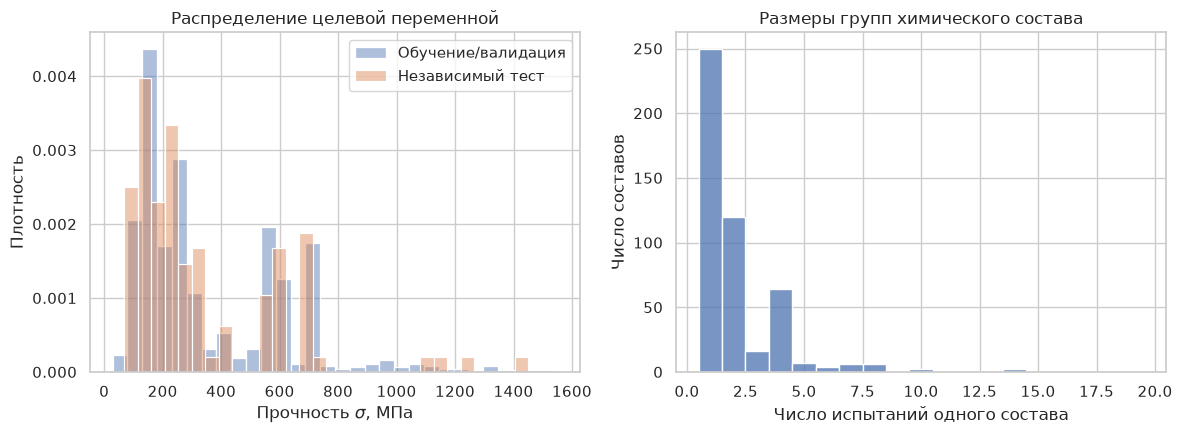

In [3]:
def choose_group_holdout(X, y, groups, test_fraction, n_candidates, seed):
    splitter = GroupShuffleSplit(
        n_splits=n_candidates,
        test_size=test_fraction,
        random_state=seed,
    )
    candidates = list(splitter.split(X, y, groups))
    train_idx, test_idx = min(
        candidates,
        key=lambda split: abs(len(split[1]) / len(y) - test_fraction),
    )
    return np.asarray(train_idx), np.asarray(test_idx)


dev_idx, test_idx = choose_group_holdout(
    X_all, y_all, groups_all,
    test_fraction=TEST_GROUP_FRACTION,
    n_candidates=N_GROUP_SPLIT_CANDIDATES,
    seed=SEED,
)

dev_groups = set(groups_all[dev_idx])
test_groups = set(groups_all[test_idx])
overlap = dev_groups & test_groups

assert not overlap, f"Composition leakage detected: {len(overlap)} groups"
assert not (set(dev_idx) & set(test_idx)), "Row leakage detected"
assert len(dev_idx) + len(test_idx) == len(y_all)

X_dev_raw, y_dev, groups_dev = X_all[dev_idx], y_all[dev_idx], groups_all[dev_idx]
X_test_raw, y_test, groups_test = X_all[test_idx], y_all[test_idx], groups_all[test_idx]

print(f"Development: {len(dev_idx)} rows, {len(dev_groups)} compositions")
print(f"Test:        {len(test_idx)} rows, {len(test_groups)} compositions")
print(f"Test row fraction: {len(test_idx) / len(y_all):.3f}")
print(f"Composition overlap: {len(overlap)}")

split_summary = pd.DataFrame({
    "split": ["development", "test"],
    "rows": [len(dev_idx), len(test_idx)],
    "composition_groups": [len(dev_groups), len(test_groups)],
    "sigma_mean_MPa": [y_dev.mean(), y_test.mean()],
    "sigma_median_MPa": [np.median(y_dev), np.median(y_test)],
    "sigma_min_MPa": [y_dev.min(), y_test.min()],
    "sigma_max_MPa": [y_dev.max(), y_test.max()],
})
display(split_summary)
split_summary.to_csv(RESULTS_DIR / "brann22_split_summary.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(y_dev, bins=30, stat="density", alpha=0.45, label="Обучение/валидация", ax=axes[0])
sns.histplot(y_test, bins=30, stat="density", alpha=0.45, label="Независимый тест", ax=axes[0])
axes[0].set_xlabel(r"Прочность $\sigma$, МПа")
axes[0].set_ylabel("Плотность")
axes[0].set_title("Распределение целевой переменной")
axes[0].legend()

group_sizes = pd.Series(groups_all).value_counts()
sns.histplot(group_sizes, discrete=True, ax=axes[1])
axes[1].set_xlabel("Число испытаний одного состава")
axes[1].set_ylabel("Число составов")
axes[1].set_title("Размеры групп химического состава")

fig.tight_layout()
fig.savefig(REPORT_IMAGE_DIR / "brann22_data_split.png", dpi=300, bbox_inches="tight")
plt.show()


## 3. Байесовская нейронная сеть

Внутри обучающего фолда и входы, и целевая переменная стандартизируются.
Для весов используется иерархический prior Стьюдента, а для наблюдений —
робастное распределение Стьюдента с обучаемым масштабом. После прогноза
результат возвращается в МПа. Перед SVI сеть преднастраивается обычным
градиентным спуском; валидационные данные в преднастройке не участвуют.

Используется последовательная сеть 48–24–12 без дополнительной линейной ветви.


In [4]:
class MLPRegressor(nn.Module):
    def __init__(self, input_dim, hidden_dims, activation="elu"):
        super().__init__()

        activations = {
            "elu": nn.ELU,
            "relu": nn.ReLU,
            "tanh": nn.Tanh,
            "silu": nn.SiLU,
            "gelu": nn.GELU,
        }
        if activation not in activations:
            raise ValueError(f"Unknown activation: {activation}")

        layers = []
        previous = input_dim
        for width in hidden_dims:
            layers.extend([nn.Linear(previous, width), activations[activation]()])
            previous = width
        layers.append(nn.Linear(previous, 1))
        self.net = nn.Sequential(*layers)
        self.reset_parameters()

    def reset_parameters(self):
        for module in self.modules():
            if isinstance(module, nn.Linear):
                nn.init.xavier_normal_(module.weight)
                nn.init.zeros_(module.bias)

    def forward(self, X):
        return self.net(X).squeeze(-1)


def site_name(prefix, name):
    return prefix + "__" + name.replace(".", "__")


def call_functional(net, params, buffers, X):
    try:
        return functional_call(net, (params, buffers), (X,))
    except TypeError:
        state = {**params, **buffers}
        return functional_call(net, state, (X,))


def make_brann_model(
    net,
    alpha_prior_shape=2.0,
    alpha_prior_rate=2.0,
    weight_df=10.0,
    observation_df=4.0,
):
    def model(X, y=None):
        alpha = pyro.sample(
            "alpha",
            dist.Gamma(
                torch.tensor(alpha_prior_shape, device=X.device, dtype=X.dtype),
                torch.tensor(alpha_prior_rate, device=X.device, dtype=X.dtype),
            ),
        )
        observation_scale = pyro.sample(
            "observation_scale",
            dist.LogNormal(
                torch.tensor(-1.0, device=X.device, dtype=X.dtype),
                torch.tensor(0.5, device=X.device, dtype=X.dtype),
            ),
        )

        weight_scale = torch.rsqrt(alpha)
        sampled_params = {}

        for name, parameter in net.named_parameters():
            prior = dist.StudentT(
                df=torch.tensor(weight_df, device=X.device, dtype=X.dtype),
                loc=torch.zeros((), device=X.device, dtype=X.dtype),
                scale=weight_scale,
            ).expand(parameter.shape).to_event(parameter.dim())
            sampled_params[name] = pyro.sample(site_name("param", name), prior)

        buffers = {
            name: buffer.to(device=X.device)
            for name, buffer in net.named_buffers()
        }
        mu = call_functional(net, sampled_params, buffers, X)
        pyro.deterministic("mu", mu)

        with pyro.plate("data", X.shape[0]):
            pyro.sample(
                "obs",
                dist.StudentT(
                    df=torch.tensor(observation_df, device=X.device, dtype=X.dtype),
                    loc=mu,
                    scale=observation_scale,
                ),
                obs=y,
            )

    return model


def make_guide(model, net):
    initial_values = {
        site_name("param", name): parameter.detach().clone().to(DEVICE)
        for name, parameter in net.named_parameters()
    }
    initial_values["alpha"] = torch.tensor(1.0, device=DEVICE, dtype=DTYPE)
    initial_values["observation_scale"] = torch.tensor(
        0.25, device=DEVICE, dtype=DTYPE
    )
    return AutoLowRankMultivariateNormal(
        model,
        rank=GUIDE_RANK,
        init_scale=GUIDE_INIT_SCALE,
        init_loc_fn=init_to_value(values=initial_values),
    )


def to_tensor(array):
    return torch.as_tensor(array, dtype=DTYPE, device=DEVICE)


def current_posterior_mu(model, guide, X_tensor, n_samples):
    with torch.no_grad():
        predictive = Predictive(
            model=model,
            guide=guide,
            num_samples=n_samples,
            return_sites=("mu",),
        )
        samples = predictive(X_tensor)["mu"]
    # Pyro can return (draws, 1, observations) or (draws, observations, 1).
    # Keep the posterior-draw axis and flatten all event/batch axes to observations.
    samples = samples.reshape(samples.shape[0], -1)
    return samples.detach().cpu().numpy()


def current_posterior_observations(model, guide, X_tensor, n_samples):
    with torch.no_grad():
        predictive = Predictive(
            model=model,
            guide=guide,
            num_samples=n_samples,
            return_sites=("obs",),
        )
        samples = predictive(X_tensor)["obs"]
    samples = samples.reshape(samples.shape[0], -1)
    return samples.detach().cpu().numpy()


def pretrain_network(net, X_tensor, y_tensor, steps):
    optimizer = torch.optim.AdamW(
        net.parameters(),
        lr=PRETRAIN_LEARNING_RATE,
        weight_decay=PRETRAIN_WEIGHT_DECAY,
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=max(int(steps), 1), eta_min=PRETRAIN_LEARNING_RATE * 0.05
    )
    objective = nn.SmoothL1Loss(beta=0.5)
    loss_history = []

    net.train()
    for step in range(1, int(steps) + 1):
        optimizer.zero_grad(set_to_none=True)
        loss = objective(net(X_tensor), y_tensor)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(net.parameters(), CLIP_NORM)
        optimizer.step()
        scheduler.step()
        if step == 1 or step % 100 == 0 or step == steps:
            loss_history.append({"step": step, "pretrain_loss": float(loss.item())})
    net.eval()
    return pd.DataFrame(loss_history)


def train_brann(
    X_train_raw,
    y_train,
    seed,
    X_val_raw=None,
    y_val=None,
    max_steps=MAX_STEPS,
    fixed_steps=None,
    verbose=True,
):
    pyro.clear_param_store()
    pyro.set_rng_seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    x_scaler = StandardScaler()
    y_scaler = StandardScaler()
    X_train = x_scaler.fit_transform(X_train_raw).astype(np.float32)
    y_train_scaled = y_scaler.fit_transform(
        np.asarray(y_train, dtype=np.float32).reshape(-1, 1)
    ).ravel().astype(np.float32)
    X_train_tensor = to_tensor(X_train)
    y_train_tensor = to_tensor(y_train_scaled)

    X_val_tensor = None
    if X_val_raw is not None:
        X_val = x_scaler.transform(X_val_raw).astype(np.float32)
        X_val_tensor = to_tensor(X_val)

    net = MLPRegressor(
        input_dim=X_train.shape[1],
        hidden_dims=HIDDEN_DIMS,
        activation=ACTIVATION,
    ).to(DEVICE)
    pretrain_history = pretrain_network(
        net, X_train_tensor, y_train_tensor, PRETRAIN_STEPS
    )

    model = make_brann_model(
        net,
        weight_df=WEIGHT_DF,
        observation_df=OBSERVATION_DF,
    )
    guide = make_guide(model, net)
    optimizer = ClippedAdam({"lr": LEARNING_RATE, "clip_norm": CLIP_NORM})
    svi = SVI(model=model, guide=guide, optim=optimizer, loss=Trace_ELBO())

    total_steps = int(fixed_steps if fixed_steps is not None else max_steps)
    history = []
    best_state = None
    best_val_mse = np.inf
    best_step = total_steps
    checks_without_improvement = 0

    iterator = range(1, total_steps + 1)
    if verbose:
        iterator = tqdm(iterator, desc=f"seed={seed}", leave=False)

    for step in iterator:
        progress = (step - 1) / max(total_steps - 1, 1)
        lr_multiplier = LR_MIN_RATIO + 0.5 * (1.0 - LR_MIN_RATIO) * (
            1.0 + np.cos(np.pi * progress)
        )
        for torch_optimizer in optimizer.optim_objs.values():
            for group in torch_optimizer.param_groups:
                group["lr"] = LEARNING_RATE * lr_multiplier

        elbo_per_sample = svi.step(X_train_tensor, y_train_tensor) / len(y_train)

        should_evaluate = (
            X_val_tensor is not None
            and step >= WARMUP_STEPS
            and step % EVAL_EVERY == 0
        )
        if should_evaluate:
            train_pred_scaled = np.median(
                current_posterior_mu(model, guide, X_train_tensor, N_POSTERIOR_VALIDATION),
                axis=0,
            )
            val_pred_scaled = np.median(
                current_posterior_mu(model, guide, X_val_tensor, N_POSTERIOR_VALIDATION),
                axis=0,
            )
            train_pred = y_scaler.inverse_transform(
                train_pred_scaled.reshape(-1, 1)
            ).ravel()
            val_pred = y_scaler.inverse_transform(
                val_pred_scaled.reshape(-1, 1)
            ).ravel()
            train_mse = mean_squared_error(y_train, train_pred)
            val_mse = mean_squared_error(y_val, val_pred)
            history.append({
                "step": step,
                "elbo_per_sample": float(elbo_per_sample),
                "train_mse": float(train_mse),
                "val_mse": float(val_mse),
            })

            relative_gain = (best_val_mse - val_mse) / max(best_val_mse, 1e-12)
            if val_mse < best_val_mse and (
                not np.isfinite(best_val_mse)
                or relative_gain >= MIN_RELATIVE_IMPROVEMENT
            ):
                best_val_mse = val_mse
                best_step = step
                best_state = copy.deepcopy(pyro.get_param_store().get_state())
                checks_without_improvement = 0
            else:
                checks_without_improvement += 1

            if checks_without_improvement >= EARLY_STOPPING_PATIENCE:
                break

    if best_state is None:
        best_state = copy.deepcopy(pyro.get_param_store().get_state())
    pyro.clear_param_store()
    pyro.get_param_store().set_state(copy.deepcopy(best_state))

    return {
        "net": net,
        "model": model,
        "guide": guide,
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
        "param_store_state": copy.deepcopy(pyro.get_param_store().get_state()),
        "best_step": int(best_step),
        "best_val_mse": float(best_val_mse),
        "history": pd.DataFrame(history),
        "pretrain_history": pretrain_history,
        "seed": int(seed),
    }


def posterior_mu_samples(fit, X_raw, n_samples):
    pyro.clear_param_store()
    pyro.get_param_store().set_state(copy.deepcopy(fit["param_store_state"]))
    X_scaled = fit["x_scaler"].transform(X_raw).astype(np.float32)
    samples_scaled = current_posterior_mu(
        fit["model"], fit["guide"], to_tensor(X_scaled), n_samples
    )
    return fit["y_scaler"].inverse_transform(
        samples_scaled.reshape(-1, 1)
    ).reshape(samples_scaled.shape)


def posterior_observation_samples(fit, X_raw, n_samples):
    pyro.clear_param_store()
    pyro.get_param_store().set_state(copy.deepcopy(fit["param_store_state"]))
    X_scaled = fit["x_scaler"].transform(X_raw).astype(np.float32)
    samples_scaled = current_posterior_observations(
        fit["model"], fit["guide"], to_tensor(X_scaled), n_samples
    )
    return fit["y_scaler"].inverse_transform(
        samples_scaled.reshape(-1, 1)
    ).reshape(samples_scaled.shape)


## 4. Групповая кросс-валидация

Кросс-валидация выполняется только на выборке для обучения и настройки.
В каждом фолде стандартизаторы обучаются только на обучающих группах.
Проверочная часть используется для выбора момента остановки и получения
OOF-прогнозов; медиана выбранных шагов задаёт длительность финального SVI.

Сохранено ограничение протокола BRANN19: проверочный фолд участвует в выборе
момента остановки, поэтому OOF-оценка может быть оптимистичной.


Fold 1/5: train=750 rows/346 groups, val=188 rows/86 groups


Fold 2/5: train=750 rows/345 groups, val=188 rows/87 groups


Fold 3/5: train=750 rows/345 groups, val=188 rows/87 groups


Fold 4/5: train=751 rows/346 groups, val=187 rows/86 groups


Fold 5/5: train=751 rows/346 groups, val=187 rows/86 groups


,fold,train_rows,validation_rows,train_groups,validation_groups,best_step,R2,MAE_MPa,RMSE_MPa,RRMSE,Median_RE,P75_RE,P90_RE,Error_le_5pct,Error_le_10pct,Error_le_20pct
0,1,750,188,346,86,2400,0.926382,38.691193,69.041061,0.303064,0.075429,0.162717,0.371439,0.398936,0.579787,0.803191
1,2,750,188,345,87,1200,0.883193,54.470923,96.216172,0.363966,0.074780,0.204343,0.411388,0.335106,0.574468,0.739362
2,3,750,188,345,87,1600,0.947308,35.680779,61.165421,0.192876,0.077084,0.127651,0.265188,0.367021,0.638298,0.835106
3,4,751,187,346,86,1200,0.911694,44.400184,76.269636,0.287248,0.092176,0.160755,0.319144,0.288770,0.561497,0.812834
4,5,751,187,346,86,800,0.902886,39.491491,71.928516,0.280151,0.077265,0.156510,0.283059,0.390374,0.577540,0.818182


,evaluation,R2,MAE_MPa,RMSE_MPa,RRMSE,Median_RE,P75_RE,P90_RE,Error_le_5pct,Error_le_10pct,Error_le_20pct
0,grouped_OOF,0.914716,42.548196,75.840524,0.290709,0.078531,0.156559,0.340349,0.356077,0.586354,0.801706


Selected final training length: 1200 SVI steps
CV time: 6.5 min


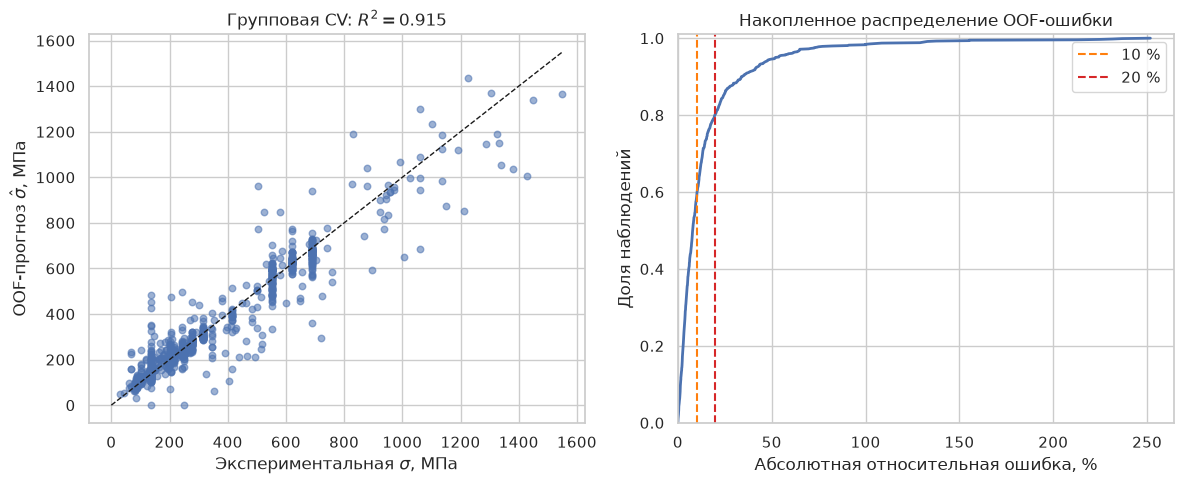

In [5]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    relative_error = np.abs(y_pred - y_true) / np.maximum(np.abs(y_true), 1e-8)
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE_MPa": mean_absolute_error(y_true, y_pred),
        "RMSE_MPa": np.sqrt(mean_squared_error(y_true, y_pred)),
        "RRMSE": np.sqrt(np.mean(relative_error ** 2)),
        "Median_RE": np.median(relative_error),
        "P75_RE": np.percentile(relative_error, 75),
        "P90_RE": np.percentile(relative_error, 90),
        "Error_le_5pct": np.mean(relative_error <= 0.05),
        "Error_le_10pct": np.mean(relative_error <= 0.10),
        "Error_le_20pct": np.mean(relative_error <= 0.20),
    }


group_kfold = GroupKFold(n_splits=N_CV_FOLDS)
oof_pred = np.full(len(y_dev), np.nan, dtype=float)
cv_fits = []
cv_rows = []

cv_start = time.time()
for fold, (train_local, val_local) in enumerate(
    group_kfold.split(X_dev_raw, y_dev, groups_dev), start=1
):
    train_groups = set(groups_dev[train_local])
    val_groups = set(groups_dev[val_local])
    assert not (train_groups & val_groups)

    print(
        f"Fold {fold}/{N_CV_FOLDS}: "
        f"train={len(train_local)} rows/{len(train_groups)} groups, "
        f"val={len(val_local)} rows/{len(val_groups)} groups"
    )
    fit = train_brann(
        X_train_raw=X_dev_raw[train_local],
        y_train=y_dev[train_local],
        X_val_raw=X_dev_raw[val_local],
        y_val=y_dev[val_local],
        seed=SEED + fold,
    )
    val_samples = posterior_mu_samples(
        fit, X_dev_raw[val_local], N_POSTERIOR_VALIDATION
    )
    val_pred = np.median(val_samples, axis=0)
    val_pred = np.clip(val_pred, 0.0, None)
    oof_pred[val_local] = val_pred

    fold_metrics = regression_metrics(y_dev[val_local], val_pred)
    cv_rows.append({
        "fold": fold,
        "train_rows": len(train_local),
        "validation_rows": len(val_local),
        "train_groups": len(train_groups),
        "validation_groups": len(val_groups),
        "best_step": fit["best_step"],
        **fold_metrics,
    })
    fit["fold"] = fold
    cv_fits.append(fit)

assert np.isfinite(oof_pred).all(), "Some development rows have no OOF prediction"

cv_metrics = regression_metrics(y_dev, oof_pred)
cv_table = pd.DataFrame(cv_rows)
display(cv_table)
display(pd.DataFrame([{"evaluation": "grouped_OOF", **cv_metrics}]))

cv_table.to_csv(RESULTS_DIR / "brann22_cv_folds.csv", index=False)
pd.DataFrame([{"evaluation": "grouped_OOF", **cv_metrics}]).to_csv(
    RESULTS_DIR / "brann22_oof_metrics.csv", index=False
)

cv_pretrain_history = pd.concat(
    [fit["pretrain_history"].assign(fold=fit["fold"]) for fit in cv_fits],
    ignore_index=True,
)
cv_svi_history = pd.concat(
    [fit["history"].assign(fold=fit["fold"]) for fit in cv_fits],
    ignore_index=True,
)
cv_pretrain_history.to_csv(
    RESULTS_DIR / "brann22_pretrain_history.csv", index=False
)
cv_svi_history.to_csv(RESULTS_DIR / "brann22_svi_history.csv", index=False)

selected_steps = int(np.median(cv_table["best_step"]))
selected_steps = max(EVAL_EVERY, selected_steps)
print(f"Selected final training length: {selected_steps} SVI steps")
print(f"CV time: {(time.time() - cv_start) / 60:.1f} min")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(y_dev, oof_pred, alpha=0.55, s=22)
lower = min(y_dev.min(), oof_pred.min())
upper = max(y_dev.max(), oof_pred.max())
axes[0].plot([lower, upper], [lower, upper], "k--", linewidth=1)
axes[0].set_xlabel(r"Экспериментальная $\sigma$, МПа")
axes[0].set_ylabel(r"OOF-прогноз $\hat{\sigma}$, МПа")
axes[0].set_title(rf"Групповая CV: $R^2={cv_metrics['R2']:.3f}$")

oof_relative_error = np.abs(oof_pred - y_dev) / np.maximum(y_dev, 1e-8)
sorted_error = np.sort(oof_relative_error * 100.0)
ecdf = np.arange(1, len(sorted_error) + 1) / len(sorted_error)
axes[1].plot(sorted_error, ecdf, linewidth=2)
axes[1].axvline(10, color="tab:orange", linestyle="--", label="10 %")
axes[1].axvline(20, color="tab:red", linestyle="--", label="20 %")
axes[1].set_xlabel("Абсолютная относительная ошибка, %")
axes[1].set_ylabel("Доля наблюдений")
axes[1].set_title("Накопленное распределение OOF-ошибки")
axes[1].set_xlim(left=0)
axes[1].set_ylim(0, 1.01)
axes[1].legend()

fig.tight_layout()
fig.savefig(REPORT_IMAGE_DIR / "brann22_oof_diagnostics.png", dpi=300, bbox_inches="tight")
plt.show()


## 5. Финальное обучение

После выбора числа шагов по кросс-валидации семь независимо инициализированных BRANN обучаются на всей development-части. Тестовые данные по-прежнему не используются. Способ объединения - медиана всех апостериорных прогнозов - был задан в конфигурации заранее.


In [6]:
final_fits = []
final_start = time.time()

for network_id in range(FINAL_ENSEMBLE_SIZE):
    seed = SEED + 10_000 + network_id
    print(f"Final network {network_id + 1}/{FINAL_ENSEMBLE_SIZE}, seed={seed}")
    fit = train_brann(
        X_train_raw=X_dev_raw,
        y_train=y_dev,
        seed=seed,
        fixed_steps=selected_steps,
        verbose=True,
    )
    fit["network_id"] = network_id + 1
    final_fits.append(fit)

print(f"Final training time: {(time.time() - final_start) / 60:.1f} min")


Final network 1/7, seed=10042


Final network 2/7, seed=10043


Final network 3/7, seed=10044


Final network 4/7, seed=10045


Final network 5/7, seed=10046


Final network 6/7, seed=10047


Final network 7/7, seed=10048


Final training time: 2.2 min


## 6. Оценка на отложенной тестовой выборке

Обученный ансамбль прогнозирует прочность для 104 записей,
соответствующих 49 составам, исключённым из обучения.

Для каждой записи рассчитываются итоговый прогноз и 90%-й
предиктивный интервал. Качество оценивается по коэффициенту
детерминации R², абсолютным и относительным ошибкам,
а также фактическому покрытию предиктивного интервала.
Этот тест ранее использовался при разработке; это оценка на фиксированной
отложенной выборке, а не новая независимая внешняя проверка.


In [7]:
posterior_blocks = []
predictive_blocks = []
for fit in tqdm(final_fits, desc="Posterior prediction"):
    posterior_blocks.append(
        posterior_mu_samples(fit, X_test_raw, N_POSTERIOR_TEST)
    )
    predictive_blocks.append(
        posterior_observation_samples(fit, X_test_raw, N_POSTERIOR_TEST)
    )

all_test_samples = np.concatenate(posterior_blocks, axis=0)
all_test_samples = np.clip(all_test_samples, 0.0, None)
all_test_predictive_samples = np.concatenate(predictive_blocks, axis=0)
all_test_predictive_samples = np.clip(all_test_predictive_samples, 0.0, None)

if FINAL_AGGREGATION != "median":
    raise ValueError("This notebook pre-registers median aggregation")

test_pred = np.median(all_test_samples, axis=0)
test_q05 = np.quantile(all_test_predictive_samples, 0.05, axis=0)
test_q95 = np.quantile(all_test_predictive_samples, 0.95, axis=0)

test_metrics = regression_metrics(y_test, test_pred)
test_metrics["PI90_coverage"] = np.mean(
    (y_test >= test_q05) & (y_test <= test_q95)
)
test_metrics["PI90_mean_width_MPa"] = np.mean(test_q95 - test_q05)
test_metrics["test_rows"] = len(test_idx)
test_metrics["test_composition_groups"] = len(set(groups_test))

metrics_table = pd.DataFrame([
    {"evaluation": "grouped_OOF", **cv_metrics},
    {"evaluation": "held_out_compositions", **test_metrics},
])
display(metrics_table.T)
metrics_table.to_csv(RESULTS_DIR / "brann22_metrics.csv", index=False)

test_results = metadata_all.iloc[test_idx].copy().reset_index(drop=True)
test_results["sigma_pred_MPa"] = test_pred
test_results["q05_MPa"] = test_q05
test_results["q95_MPa"] = test_q95
test_results["residual_MPa"] = test_pred - y_test
test_results["absolute_relative_error"] = (
    np.abs(test_pred - y_test) / np.maximum(y_test, 1e-8)
)
test_results.to_csv(RESULTS_DIR / "brann22_test_predictions.csv", index=False)

summary = {
    "protocol": {
        "architecture": "MLP without linear skip",
        "hidden_dims": HIDDEN_DIMS,
        "activation": ACTIVATION,
        "linear_skip": False,
        "network_parameters": sum(p.numel() for p in final_fits[0]["net"].parameters()),
        "grouping": f"composition rounded to {GROUP_ROUND_DECIMALS} decimals",
        "condition_feature_mode": CONDITION_FEATURE_MODE,
        "feature_names": feature_df.columns.tolist(),
        "test_group_fraction": TEST_GROUP_FRACTION,
        "cv_folds": N_CV_FOLDS,
        "final_ensemble_size": FINAL_ENSEMBLE_SIZE,
        "aggregation": FINAL_AGGREGATION,
        "selected_steps_from_cv": selected_steps,
        "target_scaling": "fold-local StandardScaler; inverse transform to MPa",
        "deterministic_pretraining_steps": PRETRAIN_STEPS,
        "observation_likelihood": f"StudentT(df={OBSERVATION_DF})",
    },
    "grouped_oof_metrics": {k: float(v) for k, v in cv_metrics.items()},
    "held_out_composition_metrics": {k: float(v) for k, v in test_metrics.items()},
}
with open(RESULTS_DIR / "brann22_summary.json", "w", encoding="utf-8") as stream:
    json.dump(summary, stream, ensure_ascii=False, indent=2)

print("Saved metrics and predictions to:", RESULTS_DIR.resolve())


Posterior prediction: 100%|██████████| 7/7 [00:28<00:00,  4.14s/it]


,0,1
evaluation,grouped_OOF,held_out_compositions
R2,0.914716,0.958746
MAE_MPa,42.548196,32.283633
RMSE_MPa,75.840524,54.130515
RRMSE,0.290709,0.283508
Median_RE,0.078531,0.056154
P75_RE,0.156559,0.13889
P90_RE,0.340349,0.377457
Error_le_5pct,0.356077,0.471154
Error_le_10pct,0.586354,0.644231


Saved metrics and predictions to: /home/syval/study/urfu/coursach/result3/urfu-latex-template/results


## 7. Графики для отчёта

Сохраняются пять готовых изображений:

- `brann22_data_split.png` - проверка разбиения данных;
- `brann22_oof_diagnostics.png` - результаты групповой CV с выбором момента остановки;
- `brann22_test_diagnostics.png` - итоговые метрики на исключённых составах;
- `brann22_test_uncertainty.png` - 90%-е интервалы неопределённости;
- `brann22_larson_miller_example.png` - пример зависимости прочности от параметра Ларсона-Миллера для тестового состава.


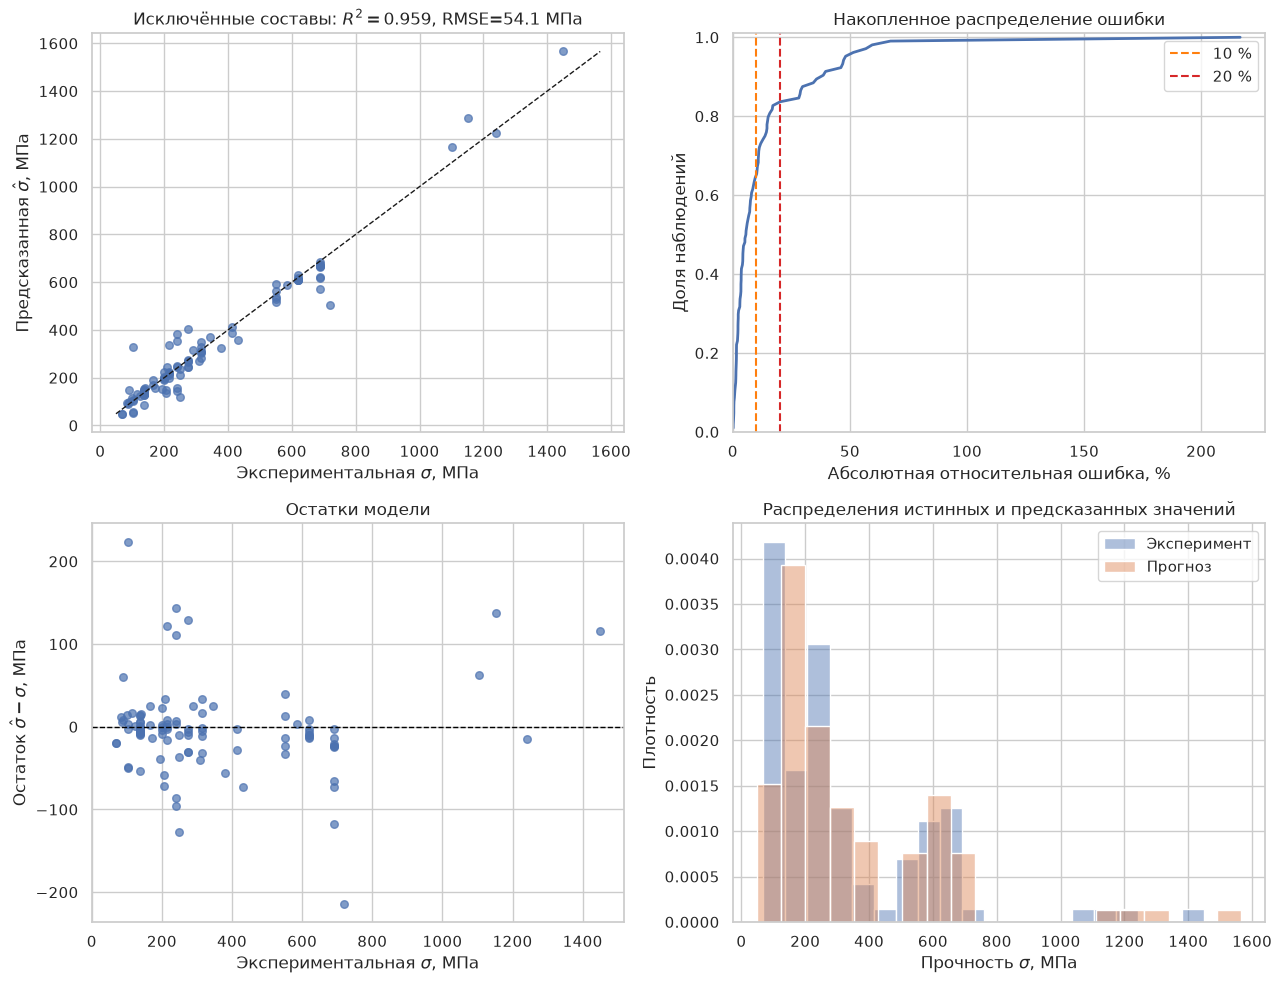

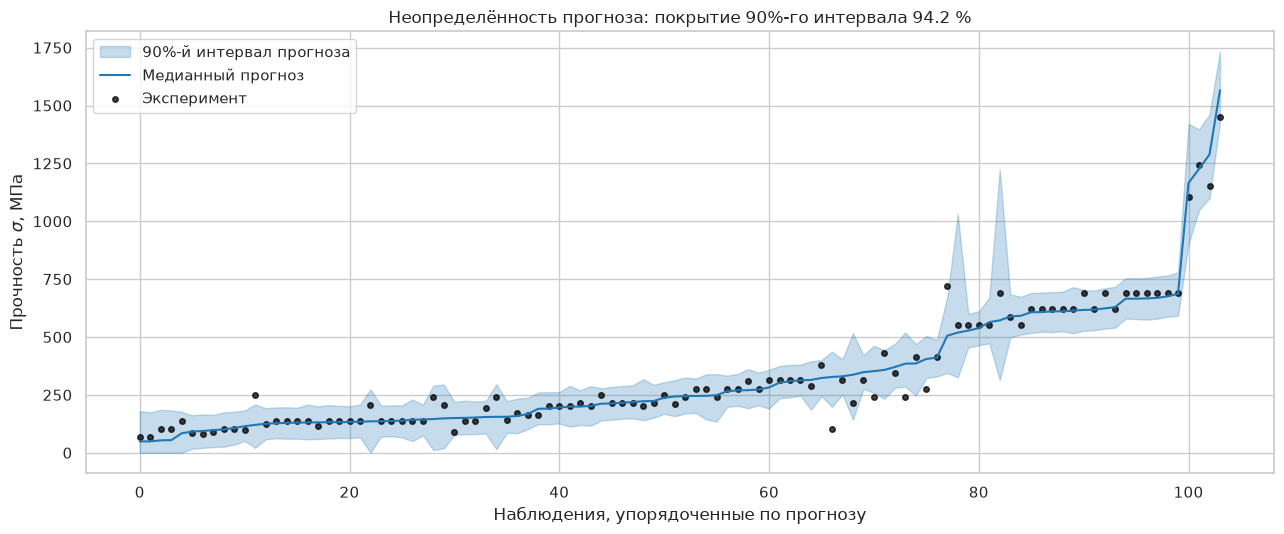

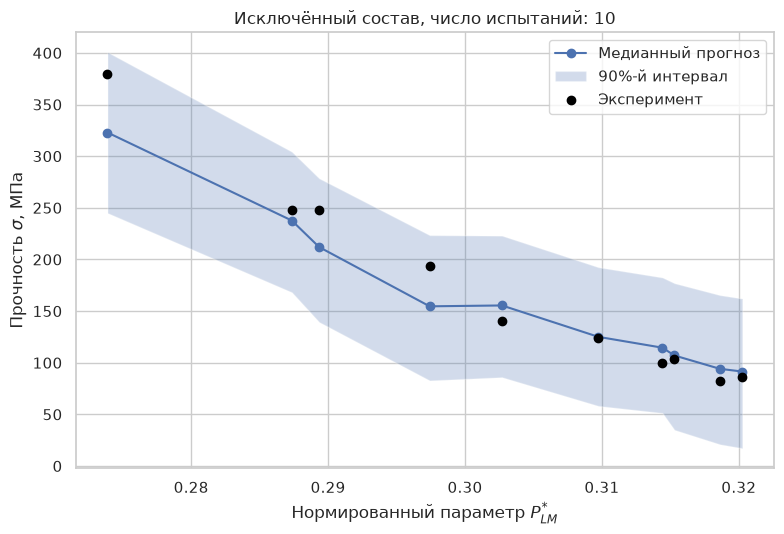

In [8]:
residuals = test_pred - y_test
relative_error_pct = np.abs(residuals) / np.maximum(y_test, 1e-8) * 100.0

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

axes[0, 0].scatter(y_test, test_pred, alpha=0.7, s=30)
lower = min(y_test.min(), test_pred.min())
upper = max(y_test.max(), test_pred.max())
axes[0, 0].plot([lower, upper], [lower, upper], "k--", linewidth=1)
axes[0, 0].set_xlabel(r"Экспериментальная $\sigma$, МПа")
axes[0, 0].set_ylabel(r"Предсказанная $\hat{\sigma}$, МПа")
axes[0, 0].set_title(
    rf"Исключённые составы: $R^2={test_metrics['R2']:.3f}$, "
    rf"RMSE={test_metrics['RMSE_MPa']:.1f} МПа"
)

sorted_error = np.sort(relative_error_pct)
ecdf = np.arange(1, len(sorted_error) + 1) / len(sorted_error)
axes[0, 1].plot(sorted_error, ecdf, linewidth=2)
axes[0, 1].axvline(10, color="tab:orange", linestyle="--", label="10 %")
axes[0, 1].axvline(20, color="tab:red", linestyle="--", label="20 %")
axes[0, 1].set_xlabel("Абсолютная относительная ошибка, %")
axes[0, 1].set_ylabel("Доля наблюдений")
axes[0, 1].set_title("Накопленное распределение ошибки")
axes[0, 1].set_xlim(left=0)
axes[0, 1].set_ylim(0, 1.01)
axes[0, 1].legend()

axes[1, 0].scatter(y_test, residuals, alpha=0.7, s=30)
axes[1, 0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 0].set_xlabel(r"Экспериментальная $\sigma$, МПа")
axes[1, 0].set_ylabel(r"Остаток $\hat{\sigma}-\sigma$, МПа")
axes[1, 0].set_title("Остатки модели")

sns.histplot(y_test, bins=20, stat="density", alpha=0.45, label="Эксперимент", ax=axes[1, 1])
sns.histplot(test_pred, bins=20, stat="density", alpha=0.45, label="Прогноз", ax=axes[1, 1])
axes[1, 1].set_xlabel(r"Прочность $\sigma$, МПа")
axes[1, 1].set_ylabel("Плотность")
axes[1, 1].set_title("Распределения истинных и предсказанных значений")
axes[1, 1].legend()

fig.tight_layout()
fig.savefig(REPORT_IMAGE_DIR / "brann22_test_diagnostics.png", dpi=300, bbox_inches="tight")
plt.show()


order = np.argsort(test_pred)
x_position = np.arange(len(test_pred))
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.fill_between(
    x_position,
    test_q05[order],
    test_q95[order],
    alpha=0.25,
    color="tab:blue",
    label="90%-й интервал прогноза",
)
ax.plot(x_position, test_pred[order], color="tab:blue", linewidth=1.5, label="Медианный прогноз")
ax.scatter(x_position, y_test[order], color="black", s=16, alpha=0.75, label="Эксперимент")
ax.set_xlabel("Наблюдения, упорядоченные по прогнозу")
ax.set_ylabel(r"Прочность $\sigma$, МПа")
ax.set_title(
    f"Неопределённость прогноза: покрытие 90%-го интервала "
    f"{test_metrics['PI90_coverage'] * 100:.1f} %"
)
ax.legend()
fig.tight_layout()
fig.savefig(REPORT_IMAGE_DIR / "brann22_test_uncertainty.png", dpi=300, bbox_inches="tight")
plt.show()


# The held-out composition with the largest number of experimental conditions.
example_group = test_results["composition_group"].value_counts().index[0]
example_mask = test_results["composition_group"].eq(example_group).to_numpy()
example = test_results.loc[example_mask].sort_values("P_LM_scaled")

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(
    example["P_LM_scaled"],
    example["sigma_pred_MPa"],
    marker="o",
    label="Медианный прогноз",
)
ax.fill_between(
    example["P_LM_scaled"].to_numpy(),
    example["q05_MPa"].to_numpy(),
    example["q95_MPa"].to_numpy(),
    alpha=0.25,
    label="90%-й интервал",
)
ax.scatter(
    example["P_LM_scaled"],
    example[TARGET_COLUMN],
    color="black",
    zorder=3,
    label="Эксперимент",
)
ax.set_xlabel(r"Нормированный параметр $P_{LM}^{*}$")
ax.set_ylabel(r"Прочность $\sigma$, МПа")
ax.set_title(f"Исключённый состав, число испытаний: {len(example)}")
ax.legend()
fig.tight_layout()
fig.savefig(REPORT_IMAGE_DIR / "brann22_larson_miller_example.png", dpi=300, bbox_inches="tight")
plt.show()


## 8. Значения для переноса в отчёт

Ячейка ниже печатает основные результаты в согласованном формате. При
сравнении улучшений ориентируйтесь прежде всего на grouped OOF.


In [9]:
def pct(value):
    return f"{100.0 * value:.2f} %"


print("ГРУППОВАЯ КРОСС-ВАЛИДАЦИЯ (OOF)")
print(f"R2 = {cv_metrics['R2']:.4f}")
print(f"MAE = {cv_metrics['MAE_MPa']:.2f} MPa")
print(f"RMSE = {cv_metrics['RMSE_MPa']:.2f} MPa")
print(f"RRMSE = {cv_metrics['RRMSE']:.4f}")
print(f"Median RE = {pct(cv_metrics['Median_RE'])}")
print(f"Error <= 20%: {pct(cv_metrics['Error_le_20pct'])}")

print("\nПРЕЖДЕ ИСКЛЮЧЁННЫЕ СОСТАВЫ (СРАВНИТЕЛЬНАЯ ОЦЕНКА)")
print(f"Rows = {test_metrics['test_rows']}")
print(f"Compositions = {test_metrics['test_composition_groups']}")
print(f"R2 = {test_metrics['R2']:.4f}")
print(f"MAE = {test_metrics['MAE_MPa']:.2f} MPa")
print(f"RMSE = {test_metrics['RMSE_MPa']:.2f} MPa")
print(f"RRMSE = {test_metrics['RRMSE']:.4f}")
print(f"Median RE = {pct(test_metrics['Median_RE'])}")
print(f"P75 RE = {pct(test_metrics['P75_RE'])}")
print(f"P90 RE = {pct(test_metrics['P90_RE'])}")
print(f"Error <= 5%: {pct(test_metrics['Error_le_5pct'])}")
print(f"Error <= 10%: {pct(test_metrics['Error_le_10pct'])}")
print(f"Error <= 20%: {pct(test_metrics['Error_le_20pct'])}")
print(f"90% interval coverage: {pct(test_metrics['PI90_coverage'])}")

print("\nFILES FOR REPORT")
for name in [
    "brann22_data_split.png",
    "brann22_oof_diagnostics.png",
    "brann22_test_diagnostics.png",
    "brann22_test_uncertainty.png",
    "brann22_larson_miller_example.png",
]:
    print(REPORT_IMAGE_DIR / name)


ГРУППОВАЯ КРОСС-ВАЛИДАЦИЯ (OOF)
R2 = 0.9147
MAE = 42.55 MPa
RMSE = 75.84 MPa
RRMSE = 0.2907
Median RE = 7.85 %
Error <= 20%: 80.17 %

ПРЕЖДЕ ИСКЛЮЧЁННЫЕ СОСТАВЫ (СРАВНИТЕЛЬНАЯ ОЦЕНКА)
Rows = 104
Compositions = 49
R2 = 0.9587
MAE = 32.28 MPa
RMSE = 54.13 MPa
RRMSE = 0.2835
Median RE = 5.62 %
P75 RE = 13.89 %
P90 RE = 37.75 %
Error <= 5%: 47.12 %
Error <= 10%: 64.42 %
Error <= 20%: 82.69 %
90% interval coverage: 94.23 %

FILES FOR REPORT
/home/syval/study/urfu/coursach/result3/urfu-latex-template/src/images/brann22_data_split.png
/home/syval/study/urfu/coursach/result3/urfu-latex-template/src/images/brann22_oof_diagnostics.png
/home/syval/study/urfu/coursach/result3/urfu-latex-template/src/images/brann22_test_diagnostics.png
/home/syval/study/urfu/coursach/result3/urfu-latex-template/src/images/brann22_test_uncertainty.png
/home/syval/study/urfu/coursach/result3/urfu-latex-template/src/images/brann22_larson_miller_example.png
